# 3 · Urgencia, transferencia al español y API

La etiqueta de urgencia sale del motivo que el consumidor eligió en el formulario del CFPB (no del texto). Las 60 quejas en español son traducciones de quejas reales del conjunto común.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))
from quejas import config
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
R = json.loads((config.REPORTES / "resultados.json").read_text(encoding="utf-8"))
fig = lambda nombre: display(Image(filename=str(config.FIGURAS / nombre)))

## 3.1 · Detección de urgencia

,enfoque,conjunto,n_quejas,n_urgentes,precision,exhaustividad,exhaustividad_ic95_bajo,exhaustividad_ic95_alto,f1,f1_ic95_bajo,f1_ic95_alto,pct_marcadas,pr_auc
0,Reglas (palabras clave),test_reciente,10770,642,0.169,0.593,0.555,0.630,0.263,0.242,0.284,20.919,NaN
1,TF-IDF + LR (umbral en val),test_reciente,10770,642,0.468,0.360,0.322,0.397,0.407,0.369,0.444,4.587,0.411
2,Reglas (palabras clave),test_comun,300,26,0.286,0.692,0.500,0.867,0.404,0.264,0.524,21.000,NaN
3,TF-IDF + LR (umbral en val),test_comun,300,26,0.609,0.538,0.353,0.750,0.571,0.389,0.733,7.667,0.556
4,4. LLM zero-shot (qwen2.5:7b),test_comun,300,26,0.375,0.462,0.261,0.655,0.414,0.238,0.556,10.667,0.273
5,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",test_comun,300,26,0.380,0.731,0.550,0.893,0.500,0.355,0.632,16.667,0.386


,tipo_urgencia,n,exhaustividad_tfidf,exhaustividad_reglas
0,amenaza_legal_embargo,74,0.189,0.608
1,ejecucion_hipotecaria,220,0.659,0.582
2,fraude,311,0.232,0.598
3,reposesion,37,0.000,0.595


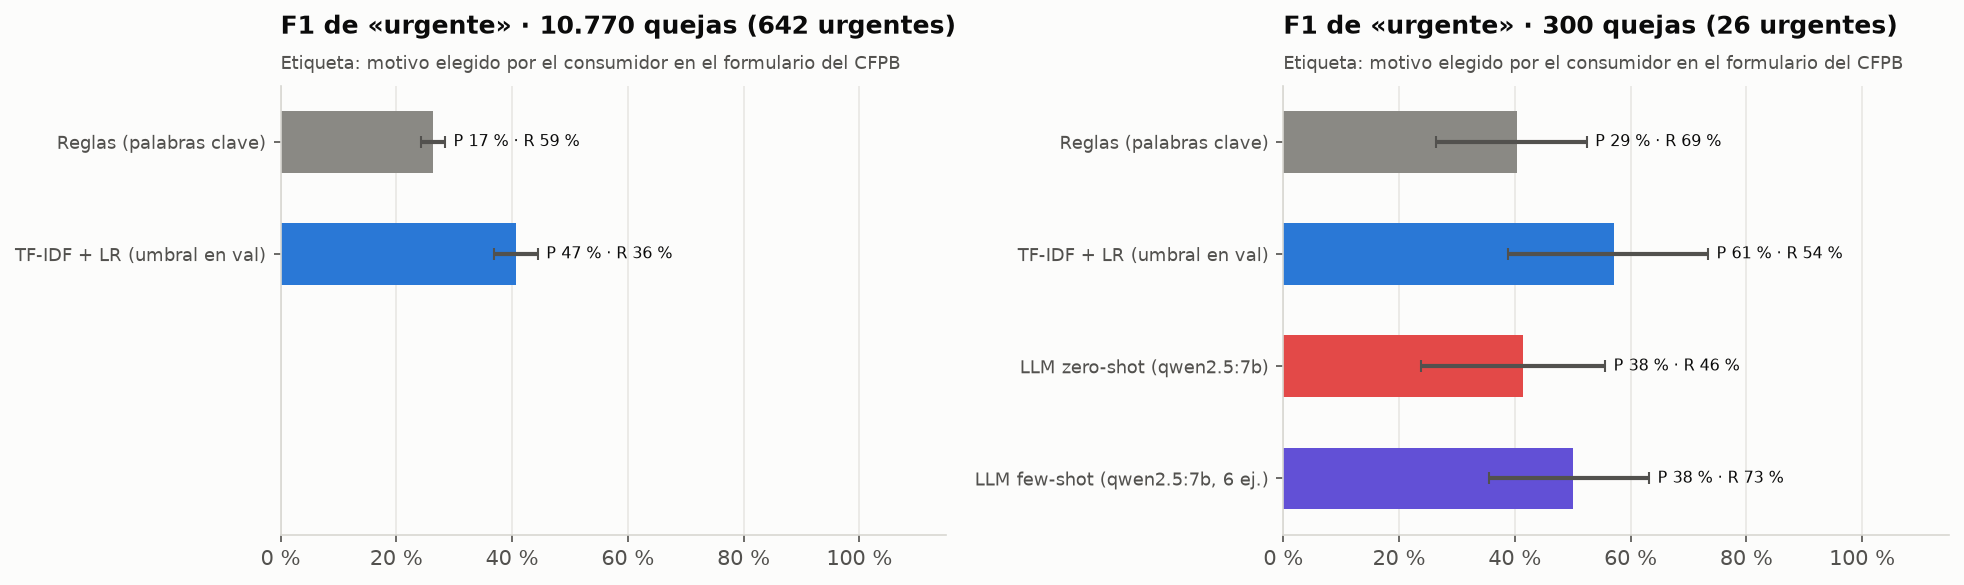

In [2]:
display(pd.read_csv(config.REPORTES / "urgencia.csv"))
display(pd.read_csv(config.REPORTES / "urgencia_por_tipo.csv"))
fig("09_urgencia.png")

## 3.2 · Las mismas quejas en inglés y en español

,enfoque,n_quejas,exactitud_ingles,exactitud_espanol,exactitud_espanol_ic95_bajo,exactitud_espanol_ic95_alto,aciertos_ingles,aciertos_espanol,f1_macro_espanol
0,1. TF-IDF + LR (25.722 ej.),60,0.867,0.483,0.350,0.600,52,29,0.488
1,2. Zero-Shot prototipos bge-m3,60,0.633,0.633,0.500,0.750,38,38,0.638
2,3. bge-m3 + LR (1.800 ej.),60,0.817,0.700,0.567,0.800,49,42,0.710
3,4. LLM zero-shot (qwen2.5:7b),60,0.617,0.583,0.466,0.717,37,35,0.592
4,"5. LLM few-shot (qwen2.5:7b, 6 ej.)",60,0.800,0.717,0.600,0.817,48,43,0.710
5,7. Cascada TF-IDF → LLM few-shot,60,0.850,0.717,0.583,0.833,51,43,0.711


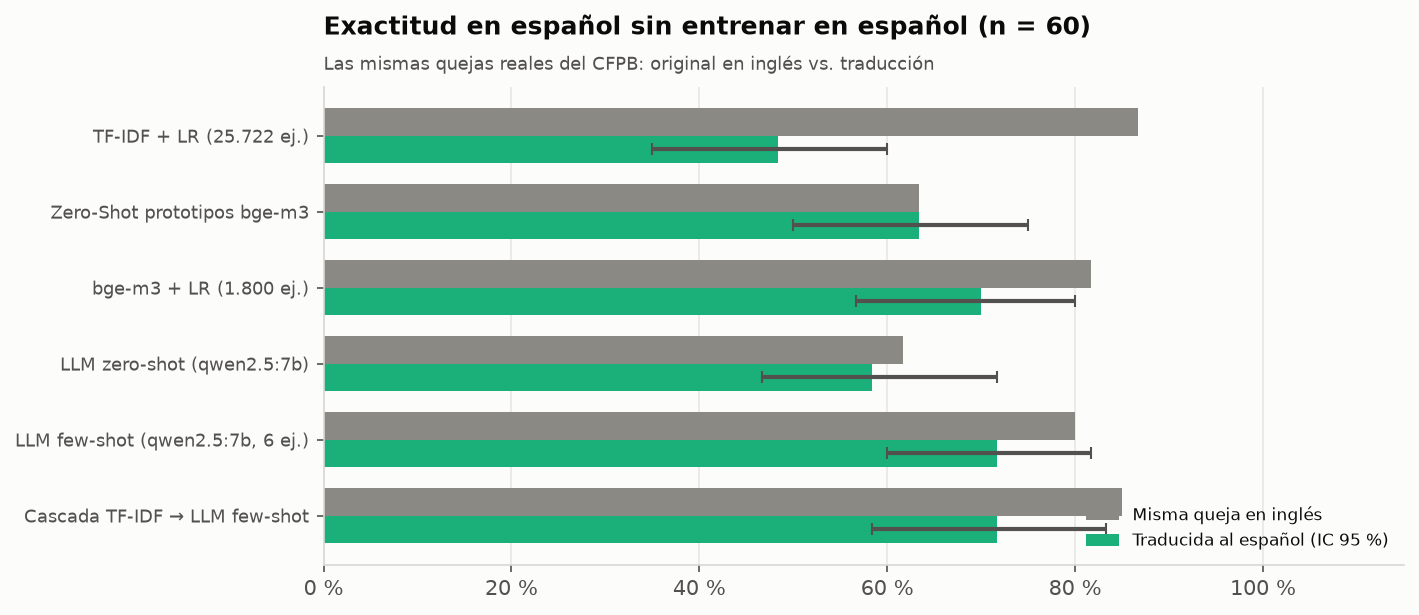

In [3]:
display(pd.read_csv(config.REPORTES / "transferencia_espanol.csv"))
fig("10_transferencia_espanol.png")

## 3.3 · API: cascada completa (`/enrutar`)

In [4]:
from fastapi.testclient import TestClient
from api.main import app
cliente = TestClient(app)
r = cliente.post("/enrutar", json={"texto_queja": "The bank started foreclosure on my home even though my loan modification is still under review."})
d = r.json()
print(d["destino_operativo"], "|", d["decidido_por"], "| prioridad:", d["prioridad"])
for p in d["pasos"]:
    print("-", p)

Mesa especialista: Hipotecas y préstamos de vivienda | TF-IDF + LR | prioridad: alta (posible fraude, ejecución, reposesión o amenaza legal)
- TF-IDF + LR propone «Hipotecas y préstamos de vivienda» con confianza calibrada 1.00 (umbral de cascada 0.70).
- Confianza suficiente: se enruta directo, sin LLM.
- Urgencia: prob. 1.00 (umbral 0.65) → prioridad alta (posible fraude, ejecución, reposesión o amenaza legal).
